# 01 · Daily bars

Daily OHLCV bars for every US-listed ticker since 2003-09-10 (about 50M rows, under 1 GB).
This notebook covers:

1. **price adjustment**: raw vs split-adjusted vs total return
2. the **point-in-time universe**: who was trading on a given day, delisted names included
3. **market-wide history**: listings, dollar volume, return tails and breadth since 2003

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from massive_subspace_stream import Store
from subspace_probe import style, timed

style()
pl.Config.set_tbl_rows(20)
pl.Config.set_tbl_width_chars(140)
store = Store()

## 1 · Raw vs adjusted prices

Bars are stored **as traded**. Adjustment happens at query time from the splits and dividends
tables, so a new split never forces rewriting history:

| `adjust=` | use it for |
|---|---|
| `None` (default) | what actually printed: order sizes, price levels, tick-size effects |
| `"splits"` | continuous price series (charts, technical signals) |
| `"all"` | splits **and** dividends: total-return series for performance and backtests |

AAPL split three times since 2003 (2:1 in 2005, 7:1 in 2014, 4:1 in 2020), so its raw prices
are not comparable over time: the two cliffs in the raw line are splits, not crashes.

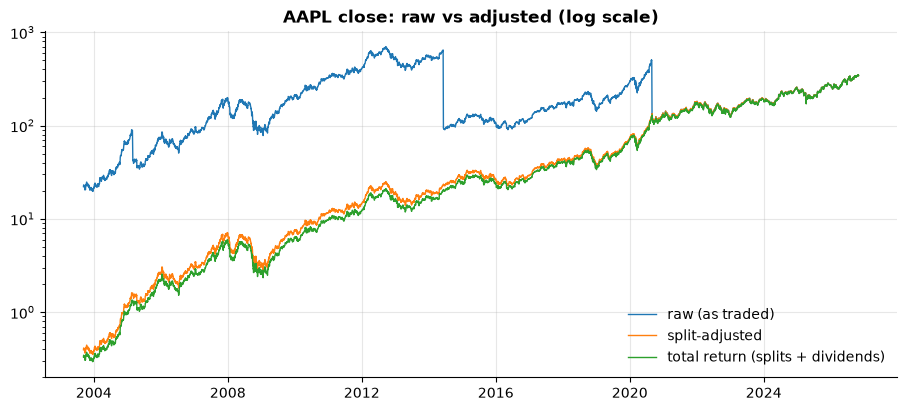

In [2]:
fig, ax = plt.subplots()
for adjust, label in [(None, "raw (as traded)"), ("splits", "split-adjusted"), ("all", "total return (splits + dividends)")]:
    df = store.bars("AAPL", start="2003-09-10", adjust=adjust, backend="pandas")
    ax.plot(df["date"], df["close"], label=label, lw=1)
ax.set_yscale("log")
ax.set_title("AAPL close: raw vs adjusted (log scale)")
ax.legend();

Adjusted queries add the factors that were applied, so the arithmetic is visible. Around the
4:1 split on 2020-08-31, the raw close drops from about \$500 to \$129 while the adjusted
close is continuous:

In [3]:
store.bars("AAPL", start="2020-08-26", end="2020-09-02", adjust="splits").select(
    "date", pl.col("close").alias("adj_close"), "split_factor",
    (pl.col("close") / pl.col("split_factor")).round(2).alias("raw_close"),
)

date,adj_close,split_factor,raw_close
date,f64,f64,f64
2020-08-26,126.5225,0.25,506.09
2020-08-27,125.01,0.25,500.04
2020-08-28,124.8075,0.25,499.23
2020-08-31,129.04,1.0,129.04
2020-09-01,134.18,1.0,134.18
2020-09-02,131.4,1.0,131.4


Dividends matter for long horizons. For Coca-Cola, reinvested dividends roughly double the
growth of the price alone since 2003:

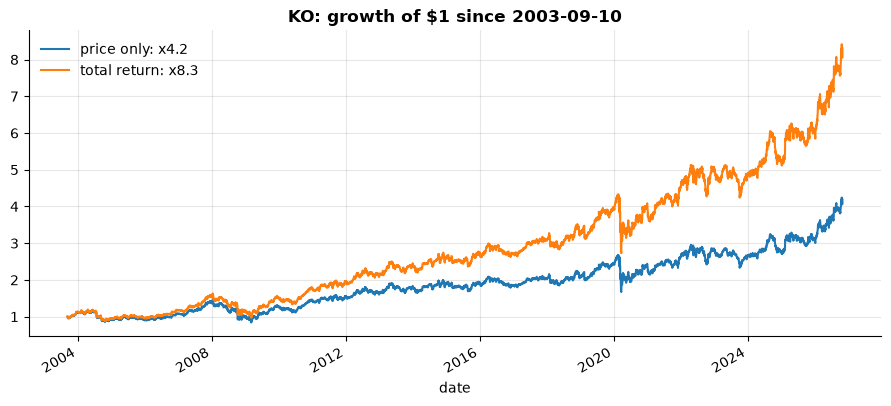

In [4]:
ko = {a: store.bars("KO", start="2003-09-10", adjust=a, backend="pandas").set_index("date")["close"] for a in ("splits", "all")}
growth = {a: s / s.iloc[0] for a, s in ko.items()}
ax = growth["splits"].plot(label=f"price only: x{growth['splits'].iloc[-1]:.1f}")
growth["all"].plot(ax=ax, label=f"total return: x{growth['all'].iloc[-1]:.1f}")
ax.set_title("KO: growth of $1 since 2003-09-10")
ax.legend();

## 2 · The point-in-time universe

`store.universe(day)` lists the tickers that actually traded on a day, built from that day's
bars, joined with reference data. Delisted companies are included, which avoids
**survivorship bias**: a backtest that starts from today's ticker list silently drops every
company that went bankrupt or was acquired.

Lehman Brothers traded on Friday 2008-09-12 and filed for bankruptcy that weekend:

In [5]:
for day in ("2008-09-12", "2008-09-19"):
    u = store.universe(day, types=["CS"])
    leh = u.filter(pl.col("ticker") == "LEH")
    print(f"{day}: {u.height:,} common stocks; LEH close = {leh['close'].item() if leh.height else 'not trading'}")

2008-09-12: 4,481 common stocks; LEH close = 3.65
2008-09-19: 4,546 common stocks; LEH close = not trading


How much of a 2008 universe no longer exists today? `active` says whether the *security*
still trades. It comes from the security master (notebook 06), so a company that was renamed
since counts as alive.

In [6]:
u08 = store.universe("2008-06-30", types=["CS"])
summary = u08.group_by("active").agg(pl.len().alias("stocks")).with_columns(
    (pl.col("stocks") / pl.col("stocks").sum() * 100).round(1).alias("pct")
)
summary

active,stocks,pct
bool,u32,f64
true,1922,42.4
false,2614,57.6


More than half of the common stocks that traded in mid-2008 are gone: delisted or acquired. A
study that only uses currently active tickers would miss all of them.

Some survivors trade under a new ticker, which matching by symbol would count as gone:

In [7]:
alive = u08.filter(pl.col("active")).join(store.securities().select("security_id", "last_ticker"), on="security_id")
renamed = alive.filter(pl.col("ticker") != pl.col("last_ticker"))
print(f"{renamed.height} of {alive.height} surviving 2008 common stocks now trade under another ticker")
renamed.select("ticker", "last_ticker", "name").filter(pl.col("ticker").is_in(["ABX", "ACXM", "ETH", "BHLB", "CU"]))

236 of 1922 surviving 2008 common stocks now trade under another ticker


ticker,last_ticker,name
str,str,str
"""BHLB""","""BBT""","""BERKSHIRE HILLS BANCORP INC"""
"""ABX""","""B""","""BARRICK GOLD CORP"""
"""ACXM""","""RAMP""","""ACXIOM CORP"""
"""CU""","""CCU""","""COMPANIA CERVECER UNIDAS ADS(5"""
"""ETH""","""ETD""","""ETHAN ALLEN INTERIORS INC"""


## 3 · Market-wide history

Whole-market questions read all 50M rows. With polars this takes a few seconds.

First, the security type of each ticker from the reference table (preferring the active row
when a symbol was reused):

In [8]:
ref = (
    store.tickers()
    .sort("active", descending=True)
    .unique("ticker", keep="first")
    .select("ticker", "type")
)
types = store.dataset("ticker_types").select(pl.col("code").alias("type"), "description")
ref = ref.with_columns(pl.col("type").fill_null("unknown"))
ref.group_by("type").agg(pl.len().alias("tickers")).join(types, on="type", how="left").sort("tickers", descending=True).head(10)

type,tickers,description
str,u32,str
"""CS""",11988,"""Common Stock"""
"""ETF""",7256,"""Exchange Traded Fund"""
"""unknown""",6738,null
"""WARRANT""",2317,"""Warrant"""
"""PFD""",2245,"""Preferred Stock"""
"""SP""",2168,"""Structured Product"""
"""UNIT""",1454,"""Unit"""
"""ADRC""",694,"""American Depository Receipt Co…"
"""FUND""",574,"""Fund"""


In [9]:
with timed("all daily bars since 2003, split-adjusted"):
    bars = store.bars(start="2003-09-10", adjust="splits", columns=["ticker", "date", "close", "volume"])
bars = bars.join(ref, on="ticker", how="left").with_columns(
    pl.col("type").fill_null("unknown"),
).with_columns(
    pl.when(pl.col("type").is_in(["CS", "ETF", "ADRC", "PFD", "WARRANT", "unknown"])).then(pl.col("type")).otherwise(pl.lit("other")).alias("group")
)
print(f"{bars.height:,} rows, {bars['ticker'].n_unique():,} tickers")

all daily bars since 2003, split-adjusted: 3.25 s


50,159,183 rows, 36,708 tickers


### Listings by type
ETFs grew from a few hundred to about 5,000, and common stocks jumped with the 2020–2021 SPAC
and IPO wave. The large `unknown` band in early years is mostly delisted tickers whose
reference record has no type (about 6,700 symbols), a reminder that old reference data is
incomplete.

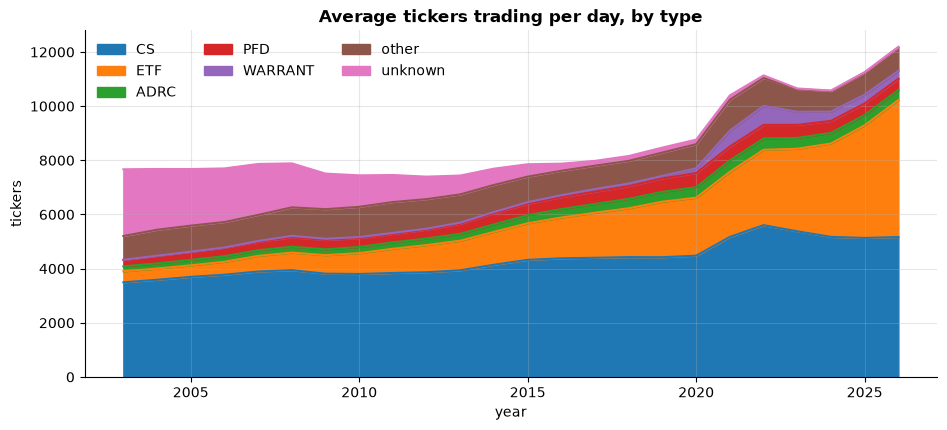

In [10]:
counts = (
    bars.group_by(pl.col("date").dt.year().alias("year"), "group")
    .agg((pl.len() / pl.col("date").n_unique()).alias("avg_tickers"))
    .pivot(on="group", index="year", values="avg_tickers")
    .sort("year")
    .to_pandas()
    .set_index("year")
)
ax = counts[["CS", "ETF", "ADRC", "PFD", "WARRANT", "other", "unknown"]].plot.area(title="Average tickers trading per day, by type")
ax.set_ylabel("tickers")
ax.legend(loc="upper left", ncol=3);

### Dollar volume
Total traded value of US stocks and ETFs per day (close × volume, 20-day average).

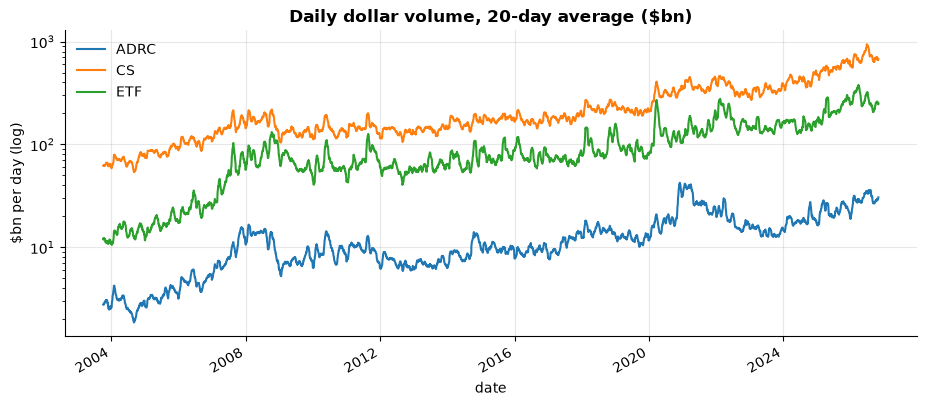

In [11]:
dv = (
    bars.filter(pl.col("group").is_in(["CS", "ETF", "ADRC"]))
    .group_by("date", "group")
    .agg((pl.col("close") * pl.col("volume")).sum().alias("dollar_volume"))
    .pivot(on="group", index="date", values="dollar_volume")
    .sort("date")
    .to_pandas()
    .set_index("date")
    .rolling(20)
    .mean()
    / 1e9
)
ax = dv.plot(title="Daily dollar volume, 20-day average ($bn)", logy=True)
ax.set_ylabel("$bn per day (log)");

### Fat tails
SPY daily total returns compared with a normal distribution of the same mean and volatility.
Extreme days happen far more often than a normal model predicts.

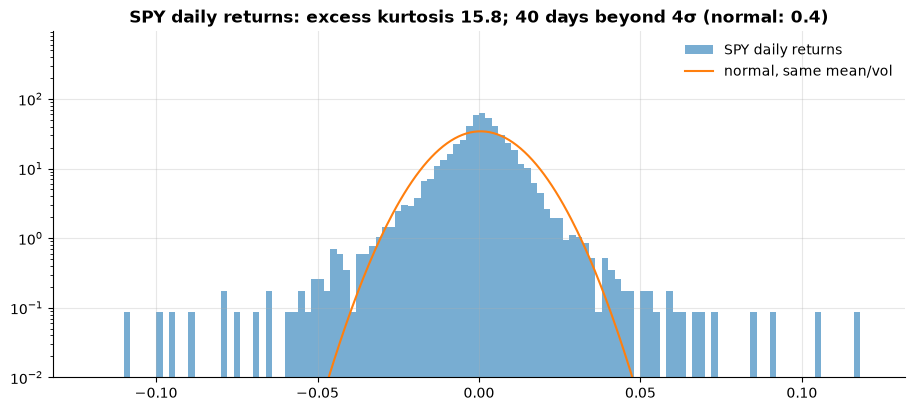

In [12]:
spy = store.bars("SPY", start="2003-09-10", adjust="all").with_columns(
    pl.col("close").pct_change().alias("ret")
).drop_nulls("ret")
r = spy["ret"].to_numpy()
mu, sigma = r.mean(), r.std()
kurt = ((r - mu) ** 4).mean() / sigma**4 - 3
beyond = (np.abs(r - mu) > 4 * sigma).sum()
expected = len(r) * 6.3e-5  # P(|z| > 4) for a normal distribution

fig, ax = plt.subplots()
bins = np.linspace(-0.12, 0.12, 121)
ax.hist(r, bins=bins, density=True, alpha=0.6, label="SPY daily returns")
x = np.linspace(-0.12, 0.12, 400)
ax.plot(x, np.exp(-((x - mu) ** 2) / (2 * sigma**2)) / (sigma * np.sqrt(2 * np.pi)), label="normal, same mean/vol")
ax.set_yscale("log")
ax.set_ylim(1e-2, None)
ax.set_title(f"SPY daily returns: excess kurtosis {kurt:.1f}; {beyond} days beyond 4σ (normal: {expected:.1f})")
ax.legend();

In [13]:
spy.select("date", (pl.col("ret") * 100).round(2).alias("ret_pct")).sort("ret_pct").pipe(
    lambda d: pl.concat([d.head(5), d.tail(5)])
)

date,ret_pct
date,f64
2020-03-16,-10.94
2008-10-15,-9.84
2020-03-12,-9.57
2008-12-01,-8.86
2008-09-29,-7.84
2020-03-13,8.55
2020-03-24,9.06
2025-04-09,10.5
2008-10-28,11.69


### Market breadth
Share of liquid common stocks (price above \$5, 20-day average dollar volume above \$1M)
trading above their own 200-day moving average. Breadth collapses in sell-offs (2008, 2011,
2020, 2022) and is a common regime indicator.

breadth over 23 years: 0.94 s


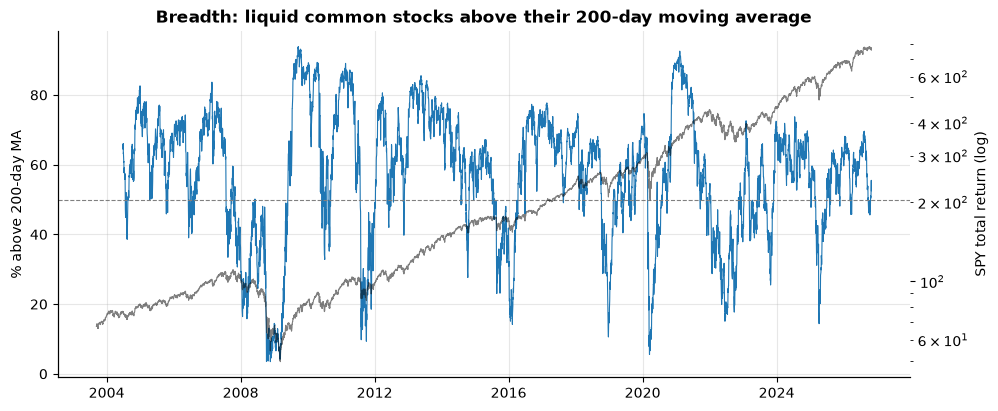

In [14]:
with timed("breadth over 23 years"):
    breadth = (
        bars.filter(pl.col("type") == "CS")
        .sort("ticker", "date")
        .with_columns(
            pl.col("close").rolling_mean(200).over("ticker").alias("ma200"),
            (pl.col("close") * pl.col("volume")).rolling_mean(20).over("ticker").alias("adv20"),
        )
        .filter(pl.col("ma200").is_not_null(), pl.col("close") > 5, pl.col("adv20") > 1e6)
        .group_by("date")
        .agg((pl.col("close") > pl.col("ma200")).mean().alias("pct_above"), pl.len().alias("stocks"))
        .sort("date")
    )

fig, ax = plt.subplots()
b = breadth.to_pandas().set_index("date")
ax.plot(b.index, b["pct_above"] * 100, lw=0.8)
ax.axhline(50, color="grey", lw=0.8, ls="--")
ax.set_ylabel("% above 200-day MA")
ax.set_title("Breadth: liquid common stocks above their 200-day moving average")
ax2 = ax.twinx()
ax2.plot(spy["date"].to_list(), spy["close"].to_list(), color="black", lw=0.8, alpha=0.5)
ax2.set_yscale("log")
ax2.set_ylabel("SPY total return (log)")
ax2.grid(False);

## Takeaways
- Use `adjust="all"` for returns and `adjust="splits"` for price levels across time;
  use raw prices only when the as-traded price matters.
- Build universes with `store.universe(day)` (or from day bars) to keep delisted names.
- Whole-market scans over daily history are fast enough to do interactively.

Next: **02 · Minute bars**.